In [2]:
from the_well.benchmark.metrics.spatial import VRMSE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import torch
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

#out_dir = '/glade/work/gaccarino/multi-scale-wavelet-flow-matching/figures'

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.well_data import get_well_dataset
from waveletflux.utils.fourier import isotropic_binning
from waveletflux.utils.eval import build_stats_df

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Get Dataset

In [3]:
well_base_path    = '/Users/gabrieleaccarino/Workspace/multi-scale-wavelet-flow-matching/data/datasets'
well_dataset_name = 'turbulent_radiative_layer_2D'

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,          # loads full trajectory
)

meta_field_names = dataset.metadata.field_names
field_names = [item for sublist in meta_field_names.values() for item in sublist]

# Load predictions

In [4]:
RESULT_DIR = f"/Users/gabrieleaccarino/Workspace/waveletflux/experiments/{well_dataset_name}/results"

model_paths = {
    "WaveletFM-1scale"  : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales" : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"       : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    "UNetConvNext"      : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
}

generative_models = ["WaveletFM-1scale", "WaveletFM-3scales"]

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)

# Evaluation Metrics

In [5]:
settings = "mean"

def horizon(t):
    if t < 20:
        return "01:33"
    elif t < 60:
        return "34:65"
    elif t < 100:
        return "66:97"
    else:
        return "101:180"
    
def aggregate(x):
    if "mean" in settings:
        return np.mean(x)
    elif "median" in settings:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

In [6]:
Ti = 4 # number of initial steps to skip (models start from these, so they are not predictions)

#lead_times = [1, 16, 32, 48, 64, 80, 96]

predictions = {
    "WaveletFM-1scale":  rollout_traj["WaveletFM-1scale"],   
    "WaveletFM-3scales": rollout_traj["WaveletFM-3scales"],      
    "UNetClassic":       rollout_traj["UNetClassic"],        
    "UNetConvNext":      rollout_traj["UNetConvNext"],       
}

palette = sns.cubehelix_palette(len(predictions.keys()), start=2, dark=0.25)

df = build_stats_df(
    truth        = truth_traj,  
    predictions  = predictions,
    field_names  = field_names,
    Ti           = Ti,
    lead_times   = None,
    stride       = 1,
)

df["horizon"] = df["time"].apply(horizon)
df["model_type"] = df["model"].apply(model_type)

In [7]:
df.columns

Index(['model', 'traj', 'field', 'step', 'time', 'm1', 'm2', 'spread', 'rmse',
       'nrmse', 'vrmse', 'spread_skill', 'total_error', 'rmse_p_low',
       'rmse_c_low', 'rmse_p_mid', 'rmse_c_mid', 'rmse_p_high', 'rmse_c_high',
       'horizon', 'model_type'],
      dtype='object')

In [8]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .mean()
    .round(4)
)
print(summary.to_string())

                               vrmse  rmse_p_low  rmse_p_mid  rmse_p_high
model             field                                                  
UNetClassic       density     0.6905      0.4928      0.6300       0.2467
                  pressure    2.7890     15.5413      6.1723       2.7366
                  velocity_x  1.2228      0.6483      0.5059       0.3165
                  velocity_y  1.3294      2.0915      1.2852       1.5355
UNetConvNext      density     0.4171      0.2261      0.2610       0.1552
                  pressure    2.5643      1.3102      0.7934       0.4344
                  velocity_x  0.5024      0.3533      0.4114       0.1804
                  velocity_y  1.0013      0.8606      0.6840       0.4387
WaveletFM-1scale  density     0.4271      0.2269      0.2802       0.1615
                  pressure    1.5892      1.1516      0.7362       0.3563
                  velocity_x  0.4876      0.3428      0.4056       0.1777
                  velocity_y  0.9477  

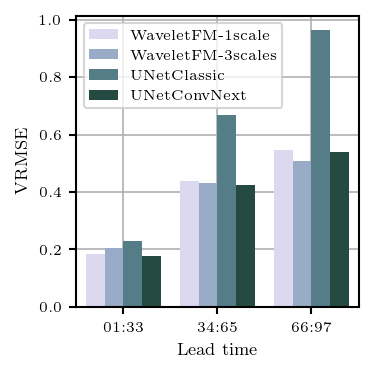

In [9]:
table = df[df["field"] == "density"]

fig = plt.figure(figsize=(2.4, 2.4))

ax = sns.barplot(
    table,
    x="horizon",
    y="vrmse",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=palette, #sns.cubehelix_palette(5, dark=0.25)[1:],
)

ax.grid()
ax.get_legend().set_title(None)

ax.set_xlabel("Lead time")
ax.set_ylabel("VRMSE")

fig.tight_layout(pad=0.33)

#plt.savefig(outdir / f"rb_ae_{settings}.pdf", dpi=300, transparent=True)
plt.show()

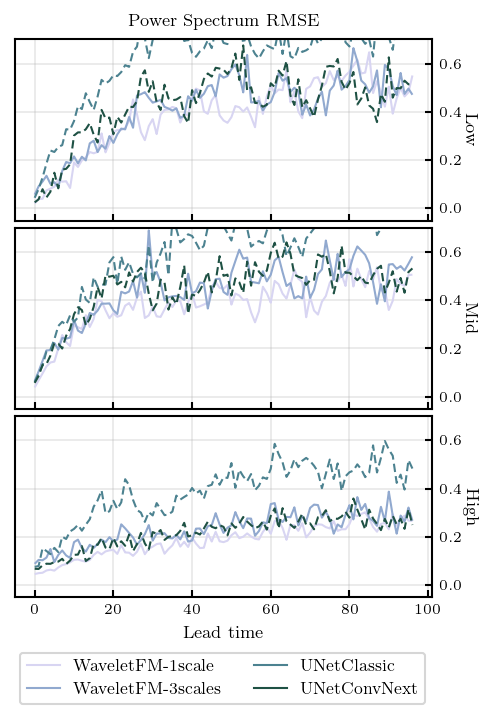

In [10]:
import seaborn as sns
import numpy as np

def aggregate(x):
    return np.median(x)

table = df

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

#palette = sns.cubehelix_palette(len(table["model"].unique()), dark=0.25)

# solid for generative, dashed for deterministic
dashes  = {"generative": (1, 0), "deterministic": (4, 2)}

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="time",
        y=f"rmse_p_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)

    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 101)

    ax.set_ylabel(band)
    ax.set_ylim(-0.05, 0.7)

    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()

    if i == 0:
        ax.set_title("Power Spectrum RMSE")
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Clean up legend: remove the "model_type" section header ───────────────────
clean = [(h, l) for h, l in zip(handles, labels) if l not in ("model_type", "generative", "deterministic", "model")]
handles_clean, labels_clean = zip(*clean)

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)  # make room at the bottom
fig.legend(handles_clean, labels_clean, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.45, 0.02))
plt.show()

# Plot PSD

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import torch
 
from waveletflux.utils.fourier import isotropic_power_spectrum
 
 
# ══════════════════════════════════════════════════════════════════════════════
# PSD DataFrame builder
# ══════════════════════════════════════════════════════════════════════════════
 
def build_psd_df(
    truth:        torch.Tensor,             # (N_TRAJ, STEPS, H, W, C)
    predictions:  dict[str, torch.Tensor],  # name -> (N_TRAJ, N_ENS, STEPS, H, W, C)
                                            #      or (N_TRAJ,        STEPS, H, W, C)
    field_names:  list[str],
    Ti:           int = 0,                  # context frames to skip (same as build_stats_df)
    lead_times:   list[int] | None = None,  # 0-indexed rollout steps; None = all
    stride:       int = 1,
    traj_indices: list[int] | None = None,
    spatial:      int = 2,
) -> pd.DataFrame:
    """
    Compute the isotropic power spectrum for every combination of:
        (model, trajectory, ensemble-member, field, lead-time, wavenumber)
 
    The returned DataFrame is in **long format** — one row per wavenumber bin —
    so that seaborn can aggregate freely (mean over traj / ens / step, CI bands, …).
 
    Columns
    -------
    model, traj, ens, field, step, time   – identifiers
    k                                     – spatial frequency  (cycles / pixel)
    wavelength                            – 1 / k              (pixels / cycle)
    psd                                   – power spectral density
 
    Notes
    -----
    * "GT" is added automatically as a model with a single ensemble member (ens=0).
    * For deterministic baselines (5-D pred tensor) ens is always 0.
    * The inner loop is vectorised over the spatial dimensions; the only Python
      loop is over (traj × field × step), which is already the same complexity
      as build_stats_df.
    """
    N_TRAJ, STEPS = truth.shape[:2]
 
    if traj_indices is None:
        traj_indices = list(range(N_TRAJ))
 
    # ── derive max usable rollout steps (mirrors build_stats_df) ─────────────
    pred_steps = []
    for pred in predictions.values():
        s = pred.shape[2] if pred.ndim == 6 else pred.shape[1]
        pred_steps.append(s)
 
    max_steps = min(STEPS - Ti, *pred_steps)
 
    if lead_times is None:
        lead_times = list(range(max_steps))
    else:
        oob = [t for t in lead_times if t >= max_steps]
        if oob:
            raise ValueError(
                f"lead_times {oob} exceed available steps ({max_steps}). "
                f"truth has {STEPS} steps, Ti={Ti}, "
                f"shortest pred has {min(pred_steps)} steps."
            )
 
    # ── helper: collect PSD rows for one (traj, field, step) slice ───────────
    def _rows_from_tensor(
        v: torch.Tensor,        # (N_ENS, H, W)  already sliced
        model_name: str,
        traj_idx: int,
        field_name: str,
        step: int,
    ) -> list[dict]:
        v = torch.as_tensor(v, dtype=torch.float32)
        p_v, k = isotropic_power_spectrum(v, spatial=spatial)  # (N_ENS, B), (B,)
 
        k_np  = k.numpy(force=True)                            # (B,)
        wl_np = np.where(k_np > 0, 1.0 / k_np, np.inf)        # (B,)
        p_np  = p_v.numpy(force=True)                          # (N_ENS, B)
 
        n_ens, n_bins = p_np.shape
        rows = []
        for ens_idx in range(n_ens):
            rows.append({
                "model":      model_name,
                "traj":       traj_idx,
                "ens":        ens_idx,
                "field":      field_name,
                "step":       step,
                "time":       step * stride,
                "k":          k_np,       # stored as array → exploded below
                "wavelength": wl_np,
                "psd":        p_np[ens_idx],
            })
        return rows
 
    # ── accumulate records (arrays, not scalars → explode once at the end) ───
    records = []
 
    # Ground truth (model="Ground-truth", ens=0)
    for traj_idx in traj_indices:
        for field_idx, field_name in enumerate(field_names):
            for step in lead_times:
                u = truth[traj_idx, Ti + step, :, :, field_idx]
                u_batch = u.unsqueeze(0)                   # (1, H, W) – fake ens dim
                records.extend(
                    _rows_from_tensor(u_batch, "Ground-truth", traj_idx, field_name, step)
                )
 
    # Predictions
    for model_name, pred in predictions.items():
        is_ensemble = pred.ndim == 6
 
        for traj_idx in traj_indices:
            for field_idx, field_name in enumerate(field_names):
                for step in lead_times:
                    if is_ensemble:
                        v = pred[traj_idx, :, step, :, :, field_idx]    # (N_ENS, H, W)
                    else:
                        v = pred[traj_idx, step, :, :, field_idx].unsqueeze(0)
                    records.extend(
                        _rows_from_tensor(v, model_name, traj_idx, field_name, step)
                    )
 
    # ── build DataFrame: each row holds arrays → explode to long format ───────
    df = pd.DataFrame(records)
    df = df.explode(["k", "wavelength", "psd"]).reset_index(drop=True)
    df["k"]          = df["k"].astype(float)
    df["wavelength"] = df["wavelength"].astype(float)
    df["psd"]        = df["psd"].astype(float)
 
    return df

In [12]:
def build_psd_df(
    truth:        torch.Tensor,             # (N_TRAJ, STEPS, H, W, C)
    predictions:  dict[str, torch.Tensor],  # name -> (N_TRAJ, N_ENS, STEPS, H, W, C)
                                            #      or (N_TRAJ,        STEPS, H, W, C)
    field_names:  list[str],
    Ti:           int = 0,                  # context frames to skip (same as build_stats_df)
    lead_times:   list[int] | None = None,  # 0-indexed rollout steps; None = all
    stride:       int = 1,
    traj_indices: list[int] | None = None,
    spatial:      int = 2,
    min_bin_count: int = 3,                 # drop frequency bins with fewer contributing
                                            # pixels than this — suppresses Nyquist noise
) -> pd.DataFrame:
    """
    Compute the isotropic power spectrum for every combination of:
        (model, trajectory, ensemble-member, field, lead-time, wavenumber)
 
    The returned DataFrame is in **long format** — one row per wavenumber bin —
    so that seaborn can aggregate freely (mean over traj / ens / step, CI bands, …).
 
    Columns
    -------
    model, traj, ens, field, step, time   – identifiers
    k                                     – spatial frequency  (cycles / pixel)
    wavelength                            – 1 / k              (pixels / cycle)
    psd                                   – power spectral density
 
    Notes
    -----
    * "GT" is added automatically as a model with a single ensemble member (ens=0).
    * For deterministic baselines (5-D pred tensor) ens is always 0.
    * Frequency bins with fewer than `min_bin_count` contributing pixels are
      dropped.  These are the isotropic corners of the 2-D spectrum (near Nyquist)
      where the radial average is based on only 1–2 pixels and produces noisy,
      model-dependent spikes at low wavelengths.  Default = 3 is conservative;
      increase to 8–16 for cleaner plots on small grids.
    * All PSD arrays are stored as Python lists (not numpy views) before being
      passed to pandas, which prevents silent k↔psd misalignment when explode()
      is called on object-dtype columns.
    """
    N_TRAJ, STEPS = truth.shape[:2]
 
    if traj_indices is None:
        traj_indices = list(range(N_TRAJ))
 
    # ── derive max usable rollout steps (mirrors build_stats_df) ─────────────
    pred_steps = []
    for pred in predictions.values():
        s = pred.shape[2] if pred.ndim == 6 else pred.shape[1]
        pred_steps.append(s)
 
    max_steps = min(STEPS - Ti, *pred_steps)
 
    if lead_times is None:
        lead_times = list(range(max_steps))
    else:
        oob = [t for t in lead_times if t >= max_steps]
        if oob:
            raise ValueError(
                f"lead_times {oob} exceed available steps ({max_steps}). "
                f"truth has {STEPS} steps, Ti={Ti}, "
                f"shortest pred has {min(pred_steps)} steps."
            )
 
    # ── pre-compute low-count bin mask once (shared grid shape for all tensors) ─
    # isotropic_binning is @cached so this is free after the first real call
    _sample_shape = tuple(int(x) for x in truth.shape[2:2 + spatial])  # (H, W)
    _edges, _counts, _ = isotropic_binning(_sample_shape, device=torch.device("cpu"))
    # Drop bins with too few contributing pixels — these are the noisy Nyquist
    # corner bins that cause the high-frequency spike on some models.
    _valid = (_counts[1:] >= min_bin_count).numpy()     # (B,) bool
 
    # ── helper: collect PSD rows for one (traj, field, step) slice ───────────
    def _rows_from_tensor(
        v: torch.Tensor,        # (N_ENS, H, W)  already sliced
        model_name: str,
        traj_idx: int,
        field_name: str,
        step: int,
    ) -> list[dict]:
        v = torch.as_tensor(v, dtype=torch.float32)
        p_v, k = isotropic_power_spectrum(v, spatial=spatial)  # (N_ENS, B), (B,)
 
        # ── owned copies, not views ─────────────────────────────────────────
        # p_v[ens_idx] would be a numpy *view* of p_np; storing views from
        # different loop iterations in a DataFrame then calling explode() can
        # silently mis-align k↔psd because pandas may evaluate the views lazily.
        # Converting to Python lists sidesteps this entirely.
        k_np  = k.numpy(force=True)[_valid]           # (B',) owned copy via bool-index
        wl_np = (1.0 / k_np)                          # (B',) all k > 0 after mask
        p_np  = p_v.numpy(force=True)[:, _valid]      # (N_ENS, B') owned copy
 
        n_ens = p_np.shape[0]
        k_list  = k_np.tolist()    # Python list — pandas explode is unambiguous
        wl_list = wl_np.tolist()   #   for any pandas version
 
        rows = []
        for ens_idx in range(n_ens):
            rows.append({
                "model":      model_name,
                "traj":       traj_idx,
                "ens":        ens_idx,
                "field":      field_name,
                "step":       step,
                "time":       step * stride,
                "k":          k_list,
                "wavelength": wl_list,
                "psd":        p_np[ens_idx].tolist(),   # .tolist() → independent copy
            })
        return rows
 
    # ── accumulate records (arrays, not scalars → explode once at the end) ───
    records = []
 
    # Ground truth (model="Ground-truth", ens=0)
    for traj_idx in traj_indices:
        for field_idx, field_name in enumerate(field_names):
            for step in lead_times:
                u = truth[traj_idx, Ti + step, :, :, field_idx]
                u_batch = u.unsqueeze(0)                   # (1, H, W) – fake ens dim
                records.extend(
                    _rows_from_tensor(u_batch, "Ground-truth", traj_idx, field_name, step)
                )
 
    # Predictions
    for model_name, pred in predictions.items():
        is_ensemble = pred.ndim == 6
 
        for traj_idx in traj_indices:
            for field_idx, field_name in enumerate(field_names):
                for step in lead_times:
                    if is_ensemble:
                        v = pred[traj_idx, :, step, :, :, field_idx]    # (N_ENS, H, W)
                    else:
                        v = pred[traj_idx, step, :, :, field_idx].unsqueeze(0)
                    records.extend(
                        _rows_from_tensor(v, model_name, traj_idx, field_name, step)
                    )
 
    # ── build DataFrame: each row holds arrays → explode to long format ───────
    df = pd.DataFrame(records)
    df = df.explode(["k", "wavelength", "psd"]).reset_index(drop=True)
    df["k"]          = df["k"].astype(float)
    df["wavelength"] = df["wavelength"].astype(float)
    df["psd"]        = df["psd"].astype(float)
 
    return df

In [13]:
psd_df = build_psd_df(
    truth = truth_traj,
    predictions = predictions,
    field_names = field_names,
    Ti = Ti,
    lead_times = None,
    stride = 1,      
    min_bin_count = 2,   
)

In [14]:
psd_df

,model,traj,ens,field,step,time,k,wavelength,psd
0,Ground-truth,0,0,density,0,0,0.007857,127.279228,1.108972e+07
1,Ground-truth,0,0,density,0,0,0.015713,63.639614,2.621086e+05
2,Ground-truth,0,0,density,0,0,0.023570,42.426411,5.667079e+04
3,Ground-truth,0,0,density,0,0,0.031427,31.819807,1.750975e+04
4,Ground-truth,0,0,density,0,0,0.039284,25.455845,9.189683e+03
...,...,...,...,...,...,...,...,...,...
1571395,UNetConvNext,8,0,velocity_y,96,96,0.675680,1.479991,1.015410e-08
1571396,UNetConvNext,8,0,velocity_y,96,96,0.683537,1.462980,1.721936e-08
1571397,UNetConvNext,8,0,velocity_y,96,96,0.691393,1.446355,1.892959e-08
1571398,UNetConvNext,8,0,velocity_y,96,96,0.699250,1.430104,3.333066e-08


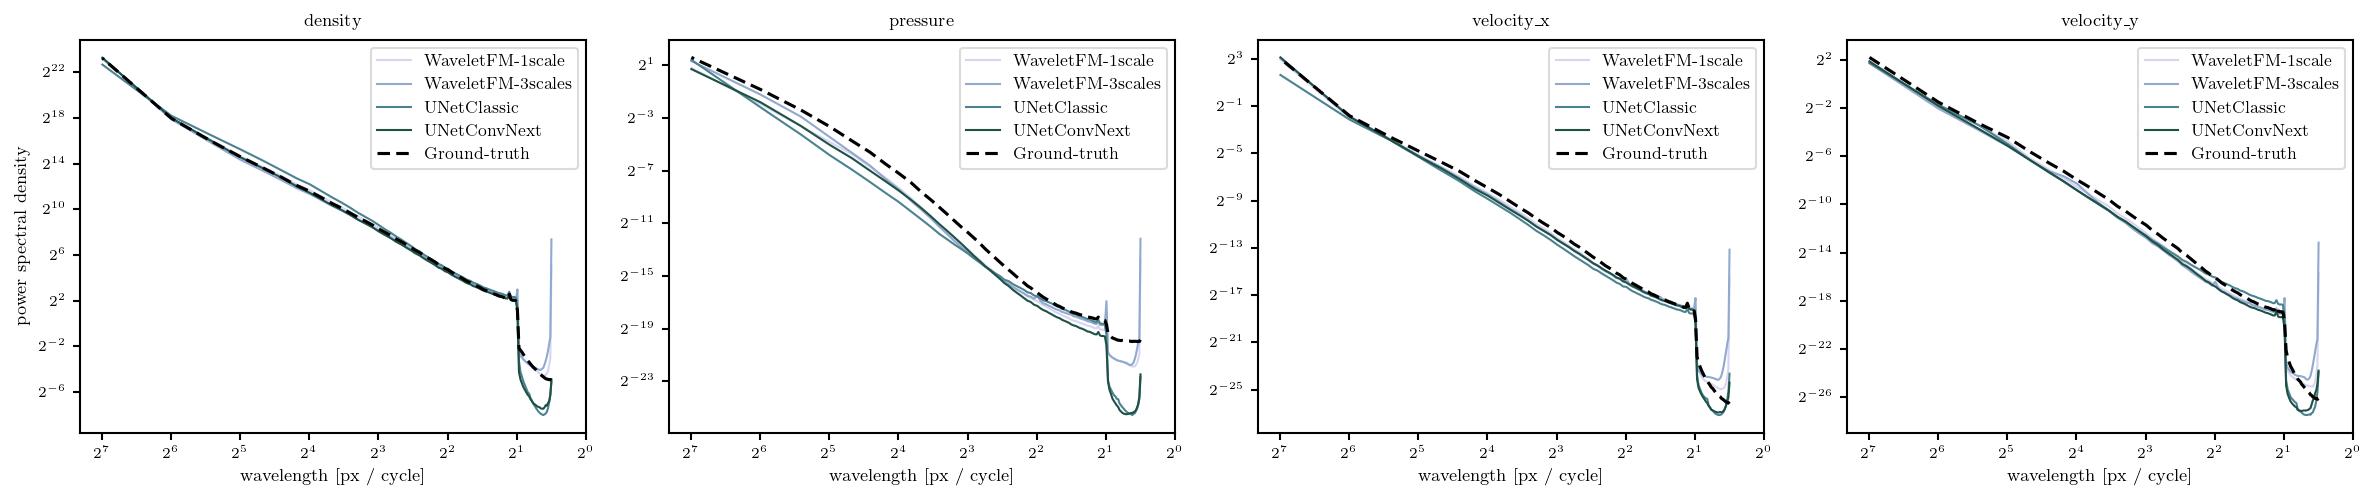

In [15]:
n_fields = len(field_names)
gt_label = "Ground-truth"
ci = None
model_lw = 1.0
gt_lw = 1.5
log_base = 2
figsize = (4.0, 3.5)

fig, axs = plt.subplots(
    1, n_fields,
    figsize=(figsize[0] * n_fields, figsize[1]),
    squeeze=False,
    sharey=False,
)

all_models = [m for m in psd_df["model"].unique() if m != gt_label]

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]

    df_field = psd_df[psd_df["field"] == field].copy()

    # ── non-GT models ──────────────────────────────────────────────────
    df_models = df_field[df_field["model"] != gt_label]

    if not df_models.empty:
        sns.lineplot(
            data=df_models,
            x="wavelength",
            y="psd",
            hue="model",
            palette=palette,
            estimator="mean",
            errorbar=("ci", ci) if ci is not None else None,
            linewidth=model_lw,
            ax=ax,
        )

    # ── Ground truth (always on top in black) ─────────────────────────
    df_gt = df_field[df_field["model"] == gt_label]

    if not df_gt.empty:
        sns.lineplot(
            data=df_gt,
            x="wavelength",
            y="psd",
            color='black',
            dashes=(4, 2),
            estimator="mean",
            errorbar=None,          # GT is deterministic → no CI band
            linewidth=gt_lw,
            label=gt_label,
            ax=ax,
        )
    
    # ── log-log scale & cosmetics ──────────────────────────────────────
    ax.set_xscale("log", base=log_base)
    ax.set_yscale("log", base=log_base)
    ax.invert_xaxis()               # large wavelengths on the left

    # Tick at every power of log_base that appears in the data
    wl_min = df_field["wavelength"].replace([np.inf], np.nan).dropna().min()
    wl_max = df_field["wavelength"].replace([np.inf], np.nan).dropna().max()
    exp_min = math.floor(math.log(wl_min, log_base))
    exp_max = math.ceil(math.log(wl_max, log_base))
    ticks = [log_base ** e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(
            plt.FuncFormatter(lambda v, _: rf"$2^{{{int(round(math.log(v, log_base)))}}}$"
                              if v > 0 else ""))

    ax.set_title(field)
    ax.set_xlabel(f"wavelength  [px / cycle]")

    if col_idx == 0:
        ax.set_ylabel("power spectral density")
    else:
        ax.set_ylabel("")

    # Keep a single, clean legend on each panel
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(handles, labels, fontsize=8, framealpha=0.7)
    else:
        ax.legend().set_visible(False)
 
    fig.align_labels()
    fig.tight_layout()
    #plt.show()

In [16]:
def plot_psd_seaborn(
    psd_df:      pd.DataFrame,
    field_names: list[str],
    *,
    # ── aggregation ────────────────────────────────────────────────────────────
    agg_over:    list[str] = ("traj", "ens", "step"),  # dims collapsed to mean
    # ── style ──────────────────────────────────────────────────────────────────
    gt_label:    str = "Ground-truth",
    palette:     str | list | None = "tab10",
    gt_color:    str = "black",
    gt_lw:       float = 2.0,
    model_lw:    float = 1.5,
    ci:          int | str | None = 95,   # seaborn errorband; None = no band
    figsize:     tuple[float, float] = (4.0, 3.5),
    log_base:    int = 2,
) -> plt.Figure:
    """
    Draw one log-log PSD panel per field.
 
    The function aggregates `psd_df` over `agg_over` dimensions (default:
    mean across trajectories, ensemble members, and lead-time steps).  The
    error band (95 % CI by default) shows variability that remains after
    averaging — e.g. across trajectories if you only average over ens/step.
 
    Parameters
    ----------
    psd_df      : DataFrame from build_psd_df
    field_names : ordered list of field labels to panel
    agg_over    : columns whose variance is collapsed by seaborn's estimator
    gt_label    : value of the "model" column that identifies ground truth
    palette     : seaborn / matplotlib palette for non-GT models
    ci          : confidence-interval width passed to sns.lineplot (int or
                  "sd"); set to None to suppress error bands
    figsize     : per-panel size; total width = figsize[0] * n_fields
    log_base    : base for both axes (2 = octave spacing, 10 = decade spacing)
 
    Returns
    -------
    matplotlib Figure
    """
    n_fields = len(field_names)
    fig, axs = plt.subplots(
        1, n_fields,
        figsize=(figsize[0] * n_fields, figsize[1]),
        squeeze=False,
        sharey=False,
    )
 
    # Separate models so GT always gets a fixed black line
    all_models = [m for m in psd_df["model"].unique() if m != gt_label]
 
    if isinstance(palette, str):
        colors = sns.color_palette(palette, n_colors=len(all_models))
    else:
        colors = palette or sns.color_palette("tab10", n_colors=len(all_models))
 
    model_palette = dict(zip(all_models, colors))
 
    for col_idx, field in enumerate(field_names):
        ax = axs[0, col_idx]
 
        df_field = psd_df[psd_df["field"] == field].copy()
 
        # ── non-GT models ──────────────────────────────────────────────────
        df_models = df_field[df_field["model"] != gt_label]
 
        if not df_models.empty:
            sns.lineplot(
                data=df_models,
                x="wavelength",
                y="psd",
                hue="model",
                palette=model_palette,
                estimator="mean",
                errorbar=("ci", ci) if ci is not None else None,
                linewidth=model_lw,
                ax=ax,
            )
 
        # ── Ground truth (always on top in black) ─────────────────────────
        df_gt = df_field[df_field["model"] == gt_label]
 
        if not df_gt.empty:
            sns.lineplot(
                data=df_gt,
                x="wavelength",
                y="psd",
                color=gt_color,
                dashes=(4, 2),
                estimator="mean",
                errorbar=None,          # GT is deterministic → no CI band
                linewidth=gt_lw,
                label=gt_label,
                ax=ax,
            )
 
        # ── log-log scale & cosmetics ──────────────────────────────────────
        ax.set_xscale("log", base=log_base)
        ax.set_yscale("log", base=log_base)
        ax.invert_xaxis()               # large wavelengths on the left
 
        # Tick at every power of log_base that appears in the data
        wl_min = df_field["wavelength"].replace([np.inf], np.nan).dropna().min()
        wl_max = df_field["wavelength"].replace([np.inf], np.nan).dropna().max()
        exp_min = math.floor(math.log(wl_min, log_base))
        exp_max = math.ceil(math.log(wl_max, log_base))
        ticks = [log_base ** e for e in range(exp_min, exp_max + 1)]
        ax.set_xticks(ticks)
        ax.xaxis.set_major_formatter(
            plt.FuncFormatter(lambda v, _: rf"$2^{{{int(round(math.log(v, log_base)))}}}$"
                              if v > 0 else ""))
 
        ax.set_title(field)
        ax.set_xlabel(f"wavelength")
        #ax.set_xlabel(f"wavelength  [px / cycle]")
 
        if col_idx == 0:
            ax.set_ylabel("power spectrum density")
        else:
            ax.set_ylabel("")
 
        # Keep a single, clean legend on each panel
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(handles, labels, fontsize=8, framealpha=0.7)
        else:
            ax.legend().set_visible(False)
 
    fig.align_labels()
    fig.tight_layout()
    return fig

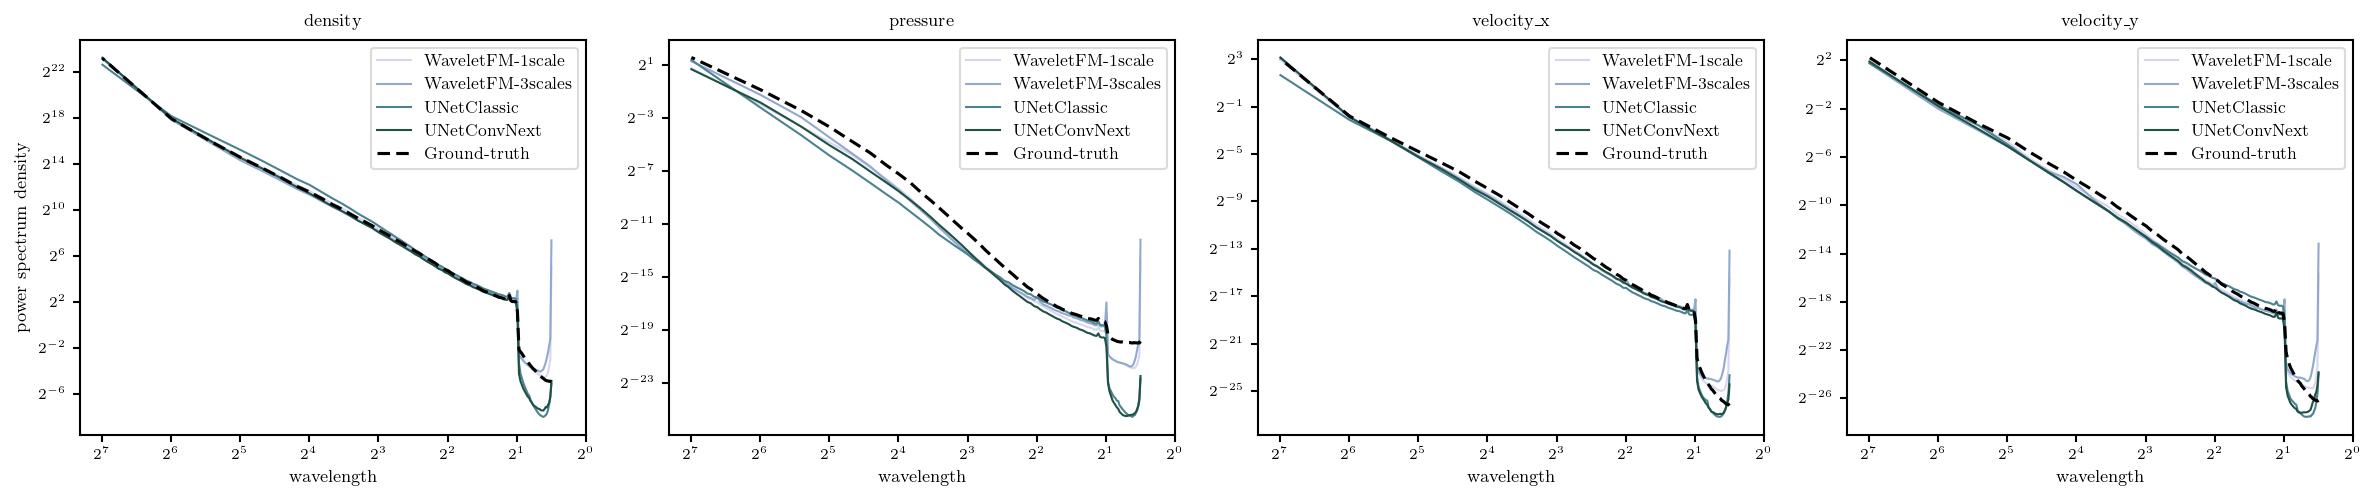

In [18]:
fig = plot_psd_seaborn(
    psd_df=psd_df,
    field_names=field_names,
    agg_over=["traj", "ens", "step"],
    gt_label="Ground-truth",
    palette=palette,
    gt_color="black",
    gt_lw=1.5,
    model_lw=1.0,
    ci=None,
    figsize=(4.0, 3.5),
    log_base=2,
)

# Tables 

In [19]:
table = df[["model", "field", "horizon", "vrmse"]]

table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
table = table.pivot(index=["model", "field"], columns="horizon", values=["vrmse"])
# print(table.to_latex(float_format="%.3f"))
table

vrmse              
horizon                       01:33  34:65  66:97
model             field                          
UNetClassic       density     0.237  0.660  1.105
                  pressure    1.255  2.577  1.893
                  velocity_x  0.418  1.448  1.714
                  velocity_y  0.810  1.265  1.328
UNetConvNext      density     0.165  0.426  0.528
                  pressure    1.169  2.114  1.887
                  velocity_x  0.201  0.449  0.642
                  velocity_y  0.651  1.030  1.154
WaveletFM-1scale  density     0.181  0.435  0.548
                  pressure    0.837  1.495  1.488
                  velocity_x  0.191  0.472  0.586
                  velocity_y  0.543  0.959  1.087
WaveletFM-3scales density     0.210  0.405  0.508
                  pressure    1.098  1.919  1.611
                  velocity_x  0.195  0.505  0.564
                  velocity_y  0.632  0.986  0.995

In [20]:
import pandas as pd

def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)

    fields = df.index.get_level_values("field").unique()

    for field, color in zip(fields, palette):
        r, g, b = [int(c * 255) for c in color[:3]]
        css = f"background-color: rgb({r},{g},{b}); color: white; font-weight: bold"

        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]           # rows for this field, all models

        for col in df.columns:
            min_idx = sub[col].idxmin()    # (model, field) index of the min
            styles.loc[min_idx, col] = css

    return styles

table.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)